# Pneumonia Detection from Chest X-Rays (DenseNet121 Transfer Learning)

**Dataset:** [Chest X-Ray Images (Pneumonia)](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia) on Kaggle (`NORMAL` vs `PNEUMONIA`).

**Pipeline**
1. Load file paths and build a proper train / val split (the official `val` folder only has 16 images, so we re-split)
2. EDA: class balance and sample images
3. `tf.data` pipeline with augmentation
4. DenseNet121 (ImageNet weights): train the head, then fine-tune
5. Evaluate on the official test set: report, confusion matrix, ROC / PR curves
6. Threshold tuning on validation data
7. Grad-CAM explainability
8. Save the model and predict on a single image

> Run on Kaggle (add the dataset, enable a GPU) or Colab/local (set `DATA_DIR` below).

**Disclaimer:** educational project only, not a medical diagnostic tool.

In [8]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [9]:
import os, random, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.densenet import preprocess_input
from sklearn.model_selection import train_test_split

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix, roc_curve, auc,
                             precision_recall_curve, average_precision_score, f1_score)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [10]:
# ---- Dataset location ----
# Kaggle:  /kaggle/input/chest-xray-pneumonia/chest_xray
# Local / Colab: path to the extracted 'chest_xray' folder
DATA_DIR = pathlib.Path("/kaggle/input/chest-xray-pneumonia/chest_xray")
if not DATA_DIR.exists():
    DATA_DIR = pathlib.Path("chest_xray")   # fallback for local use

# Some downloads nest the folder twice (chest_xray/chest_xray)
if (DATA_DIR / "chest_xray").exists():
    DATA_DIR = DATA_DIR / "chest_xray"

print("Using:", DATA_DIR.resolve())
assert DATA_DIR.exists(), "Dataset not found. Set DATA_DIR correctly."

CLASS_NAMES = ["NORMAL", "PNEUMONIA"]   # label 0 / 1

def list_split(split):
    rows = []
    for label, cls in enumerate(CLASS_NAMES):
        for p in (DATA_DIR / split / cls).glob("*"):
            if p.suffix.lower() in (".jpeg", ".jpg", ".png"):
                rows.append((str(p), label, cls))
    return pd.DataFrame(rows, columns=["path", "label", "class"])

train_df_raw = list_split("train")
val_df_raw   = list_split("val")
test_df      = list_split("test")

# Official val has only 16 images -> merge with train, then stratified re-split
full_train = pd.concat([train_df_raw, val_df_raw], ignore_index=True)
train_df, val_df = train_test_split(full_train, test_size=0.15, stratify=full_train["label"], random_state=SEED)
train_df, val_df = train_df.reset_index(drop=True), val_df.reset_index(drop=True)

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s}: {len(d):5d} images | {d['class'].value_counts().to_dict()}")

Using: /home/student/Downloads/chest_xray/chest_xray
train:  4447 images | {'PNEUMONIA': 3300, 'NORMAL': 1147}
val  :   785 images | {'PNEUMONIA': 583, 'NORMAL': 202}
test :   624 images | {'PNEUMONIA': 390, 'NORMAL': 234}


## 1. Exploratory data analysis

/tmp/ipykernel_11090/303591275.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="class", data=d, order=CLASS_NAMES, ax=ax, palette=["#4C9BE8", "#E8624C"])
/tmp/ipykernel_11090/303591275.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="class", data=d, order=CLASS_NAMES, ax=ax, palette=["#4C9BE8", "#E8624C"])
/tmp/ipykernel_11090/303591275.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="class", data=d, order=CLASS_NAMES, ax=ax, palette=["#4C9BE8", "#E8624C"])


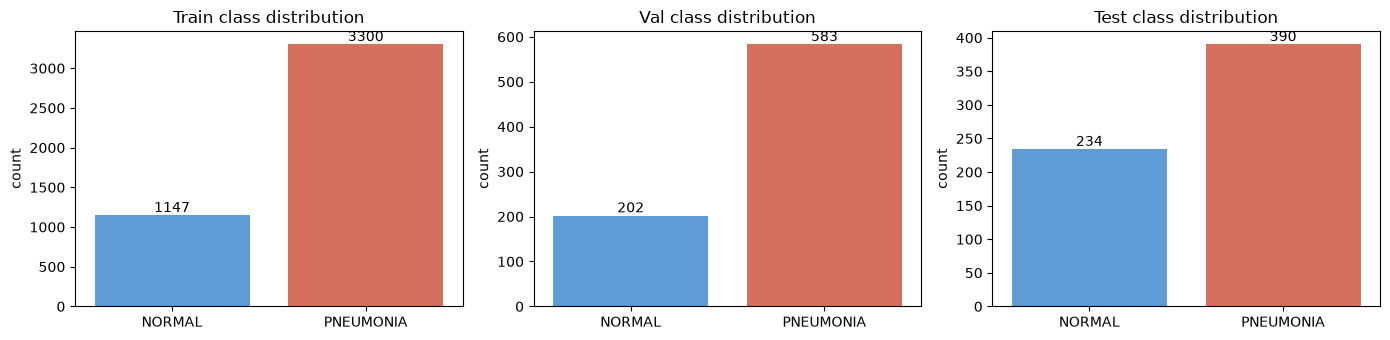

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, (name, d) in zip(axes, [("Train", train_df), ("Val", val_df), ("Test", test_df)]):
    sns.countplot(x="class", data=d, order=CLASS_NAMES, ax=ax, palette=["#4C9BE8", "#E8624C"])
    ax.set_title(f"{name} class distribution"); ax.set_xlabel("")
    for c in ax.containers: ax.bar_label(c)
plt.tight_layout(); plt.show()

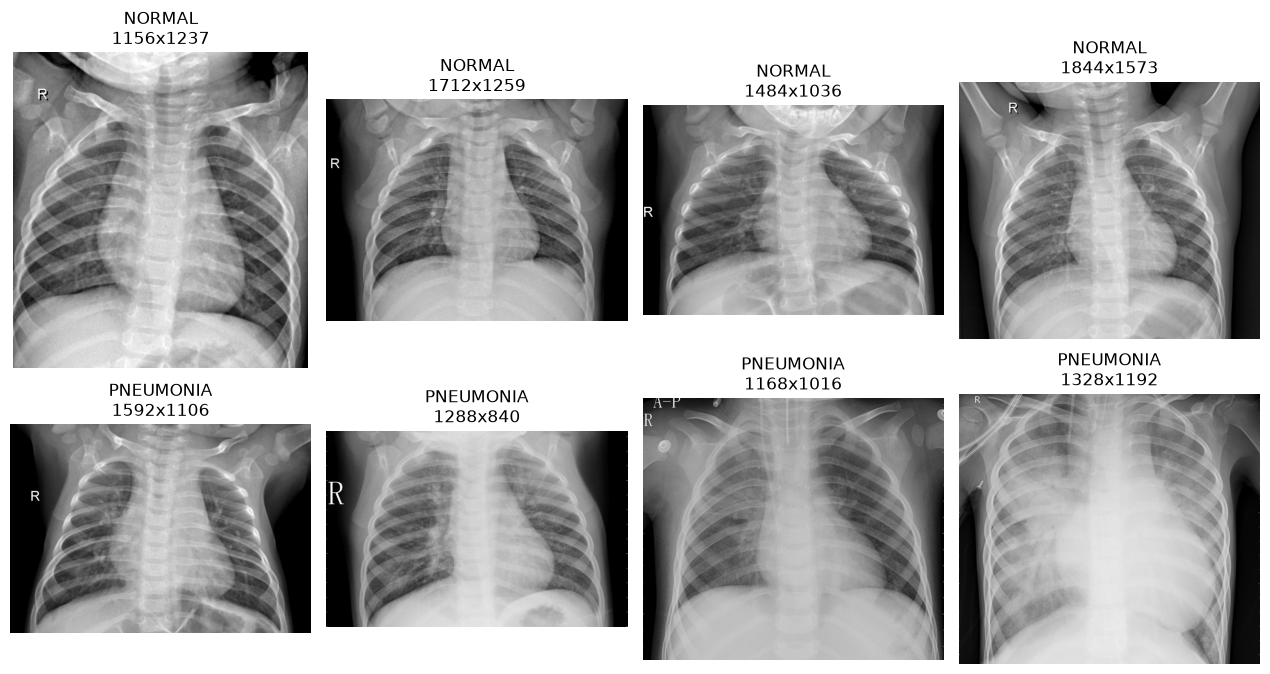

In [12]:
def show_samples(df, n=4):
    fig, axes = plt.subplots(2, n, figsize=(3.2 * n, 7))
    for r, cls in enumerate(CLASS_NAMES):
        subset = df[df["class"] == cls].sample(n, random_state=SEED)
        for c, p in enumerate(subset["path"]):
            img = keras.utils.load_img(p, color_mode="grayscale")
            axes[r, c].imshow(img, cmap="gray"); axes[r, c].axis("off")
            axes[r, c].set_title(f"{cls}\n{img.size[0]}x{img.size[1]}")
    plt.tight_layout(); plt.show()

show_samples(train_df)

## 2. Input pipeline
Chest X-rays are grayscale, so we replicate to 3 channels for ImageNet weights. Augmentation is mild (small rotation, zoom, contrast). Horizontal flips are skipped since the heart sits on the left in X-rays.

In [17]:
augment = keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomContrast(0.15),
], name="augment")

# ---- Drop images TensorFlow cannot decode ----
def is_valid(p):
    try:
        img = tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
        return img.shape.rank == 3
    except Exception:
        return False

for name in ["train_df", "val_df", "test_df"]:
    df = globals()[name]
    ok = df["path"].map(is_valid)
    print(f"{name}: {(~ok).sum()} bad file(s)")
    if (~ok).any():
        print("  ", df.loc[~ok, "path"].tolist())
    globals()[name] = df[ok].reset_index(drop=True)

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img.set_shape((*IMG_SIZE, 3))
    return img, tf.cast(label, tf.float32)

def prep(img, label):
    return preprocess_input(img), label

def make_ds(df, training=False):
    ds = tf.data.Dataset.from_tensor_slices((df["path"].values, df["label"].values))
    if training:
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.ignore_errors()          # safety net: skip any file that still fails
    if training:
        ds = ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE)
    ds = ds.map(prep, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(train_df, training=True)
val_ds   = make_ds(val_df)
test_ds  = make_ds(test_df)

cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=train_df["label"].values)
class_weight = {0: cw[0], 1: cw[1]}
print("Class weights:", class_weight)

2026-11-16 10:19:13.975042: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: INVALID_ARGUMENT: Input is empty.


train_df: 4 bad file(s)
   ['chest_xray/chest_xray/train/NORMAL/NORMAL2-IM-1204-0001.jpeg', 'chest_xray/chest_xray/train/NORMAL/NORMAL2-IM-1203-0001.jpeg', 'chest_xray/chest_xray/train/NORMAL/NORMAL2-IM-1202-0001.jpeg', 'chest_xray/chest_xray/train/NORMAL/NORMAL2-IM-1201-0001.jpeg']
val_df: 0 bad file(s)
test_df: 0 bad file(s)
Class weights: {0: np.float64(1.9435695538057742), 1: np.float64(0.6731818181818182)}


## 3. Model: DenseNet121 transfer learning

In [18]:
def build_model(dropout=0.4):
    base = DenseNet121(include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
    base.trainable = False
    x = layers.GlobalAveragePooling2D(name="gap")(base.output)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(dropout / 2)(x)
    out = layers.Dense(1, activation="sigmoid", name="pneumonia_prob")(x)
    return keras.Model(base.input, out, name="densenet121_pneumonia"), base

model, base = build_model()

metrics = [
    keras.metrics.BinaryAccuracy(name="acc"),
    keras.metrics.Precision(name="precision"),
    keras.metrics.Recall(name="recall"),
    keras.metrics.AUC(name="auc"),
]
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=metrics)
print("Trainable params:", sum(int(np.prod(w.shape)) for w in model.trainable_weights))

Trainable params: 131329


In [19]:
os.makedirs("outputs", exist_ok=True)

def callbacks(path):
    return [
        keras.callbacks.ModelCheckpoint(path, monitor="val_auc", mode="max", save_best_only=True, verbose=1),
        keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=5, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7, verbose=1),
    ]

# Phase 1: train the new head only
hist1 = model.fit(train_ds, validation_data=val_ds, epochs=8,
                  class_weight=class_weight, callbacks=callbacks("outputs/phase1.keras"))

Epoch 1/8


/opt/anaconda3/envs/ai_gpu/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


    139/Unknown 42s 225ms/step - acc: 0.8332 - auc: 0.9118 - loss: 0.3775 - precision: 0.9417 - recall: 0.8267

2026-11-16 10:20:11.095259: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key hash: 14115142744642108170
/opt/anaconda3/envs/ai_gpu/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_auc improved from None to 0.98827, saving model to outputs/phase1.keras

Epoch 1: finished saving model to outputs/phase1.keras
139/139 ━━━━━━━━━━━━━━━━━━━━ 58s 345ms/step - acc: 0.8332 - auc: 0.9118 - loss: 0.3775 - precision: 0.9417 - recall: 0.8267 - val_acc: 0.9516 - val_auc: 0.9883 - val_loss: 0.1325 - val_precision: 0.9690 - val_recall: 0.9657 - learning_rate: 0.0010
Epoch 2/8
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step - acc: 0.8859 - auc: 0.9557 - loss: 0.2702 - precision: 0.9562 - recall: 0.8870
Epoch 2: val_auc did not improve from 0.98827
139/139 ━━━━━━━━━━━━━━━━━━━━ 27s 193ms/step - acc: 0.8859 - auc: 0.9557 - loss: 0.2702 - precision: 0.9562 - recall: 0.8870 - val_acc: 0.8395 - val_auc: 0.9879 - val_loss: 0.3698 - val_precision: 1.0000 - val_recall: 0.7839 - learning_rate: 0.0010
Epoch 3/8


2026-11-16 10:20:54.524868: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
	 [[{{node IteratorGetNext}}]]
	 [[IteratorGetNext/_2]]


139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - acc: 0.9014 - auc: 0.9631 - loss: 0.2431 - precision: 0.9680 - recall: 0.8970
Epoch 3: val_auc improved from 0.98827 to 0.98990, saving model to outputs/phase1.keras

Epoch 3: finished saving model to outputs/phase1.keras
139/139 ━━━━━━━━━━━━━━━━━━━━ 28s 199ms/step - acc: 0.9014 - auc: 0.9631 - loss: 0.2431 - precision: 0.9680 - recall: 0.8970 - val_acc: 0.9580 - val_auc: 0.9899 - val_loss: 0.1262 - val_precision: 0.9808 - val_recall: 0.9623 - learning_rate: 0.0010
Epoch 4/8
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - acc: 0.9016 - auc: 0.9625 - loss: 0.2458 - precision: 0.9652 - recall: 0.9000
Epoch 4: val_auc improved from 0.98990 to 0.99235, saving model to outputs/phase1.keras

Epoch 4: finished saving model to outputs/phase1.keras
139/139 ━━━━━━━━━━━━━━━━━━━━ 28s 199ms/step - acc: 0.9016 - auc: 0.9625 - loss: 0.2458 - precision: 0.9652 - recall: 0.9000 - val_acc: 0.9414 - val_auc: 0.9924 - val_loss: 0.1522 - val_precision: 0.9963 - val

2026-11-16 10:22:45.041097: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
	 [[{{node IteratorGetNext}}]]
	 [[IteratorGetNext/_2]]



Epoch 6: finished saving model to outputs/phase1.keras
139/139 ━━━━━━━━━━━━━━━━━━━━ 28s 201ms/step - acc: 0.9097 - auc: 0.9720 - loss: 0.2142 - precision: 0.9683 - recall: 0.9082 - val_acc: 0.9414 - val_auc: 0.9931 - val_loss: 0.1650 - val_precision: 1.0000 - val_recall: 0.9211 - learning_rate: 3.0000e-04
Epoch 7/8
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step - acc: 0.9154 - auc: 0.9719 - loss: 0.2116 - precision: 0.9698 - recall: 0.9145
Epoch 7: val_auc did not improve from 0.99307

Epoch 7: ReduceLROnPlateau reducing learning rate to 9.000000427477062e-05.
139/139 ━━━━━━━━━━━━━━━━━━━━ 27s 197ms/step - acc: 0.9154 - auc: 0.9719 - loss: 0.2116 - precision: 0.9698 - recall: 0.9145 - val_acc: 0.9312 - val_auc: 0.9930 - val_loss: 0.1824 - val_precision: 1.0000 - val_recall: 0.9074 - learning_rate: 3.0000e-04
Epoch 8/8
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step - acc: 0.9151 - auc: 0.9753 - loss: 0.2013 - precision: 0.9710 - recall: 0.9130
Epoch 8: val_auc did not improve from 0.99307
139/1

In [20]:
# Phase 2: fine-tune the last ~40 layers (BatchNorm layers stay frozen)
base.trainable = True
for layer in base.layers[:-40]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5), loss="binary_crossentropy", metrics=metrics)
print("Trainable params:", sum(int(np.prod(w.shape)) for w in model.trainable_weights))

hist2 = model.fit(train_ds, validation_data=val_ds, epochs=15,
                  class_weight=class_weight, callbacks=callbacks("outputs/best_model.keras"))

Trainable params: 946433
Epoch 1/15
    139/Unknown 43s 220ms/step - acc: 0.9233 - auc: 0.9794 - loss: 0.1922 - precision: 0.9796 - recall: 0.9158
Epoch 1: val_auc improved from None to 0.99328, saving model to outputs/best_model.keras

Epoch 1: finished saving model to outputs/best_model.keras
139/139 ━━━━━━━━━━━━━━━━━━━━ 56s 317ms/step - acc: 0.9233 - auc: 0.9794 - loss: 0.1922 - precision: 0.9796 - recall: 0.9158 - val_acc: 0.9631 - val_auc: 0.9933 - val_loss: 0.1193 - val_precision: 0.9964 - val_recall: 0.9537 - learning_rate: 1.0000e-05
Epoch 2/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step - acc: 0.9192 - auc: 0.9777 - loss: 0.1910 - precision: 0.9709 - recall: 0.9188
Epoch 2: val_auc improved from 0.99328 to 0.99364, saving model to outputs/best_model.keras

Epoch 2: finished saving model to outputs/best_model.keras
139/139 ━━━━━━━━━━━━━━━━━━━━ 29s 207ms/step - acc: 0.9192 - auc: 0.9777 - loss: 0.1910 - precision: 0.9709 - recall: 0.9188 - val_acc: 0.9605 - val_auc: 0.9936 - val_

2026-11-16 10:27:04.975798: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key hash: 14115142744642108170
2026-11-16 10:27:04.975814: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key hash: 16731224589190450392
2026-11-16 10:27:04.975817: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key hash: 6520580187303138724



Epoch 6: val_auc did not improve from 0.99420
139/139 ━━━━━━━━━━━━━━━━━━━━ 28s 203ms/step - acc: 0.9298 - auc: 0.9814 - loss: 0.1708 - precision: 0.9767 - recall: 0.9276 - val_acc: 0.9567 - val_auc: 0.9938 - val_loss: 0.1341 - val_precision: 1.0000 - val_recall: 0.9417 - learning_rate: 9.0000e-07
Epoch 7/15


2026-11-16 10:27:08.859514: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
	 [[{{node IteratorGetNext}}]]
	 [[IteratorGetNext/_2]]


139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - acc: 0.9325 - auc: 0.9818 - loss: 0.1701 - precision: 0.9759 - recall: 0.9321

2026-11-16 10:27:33.288059: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key hash: 14115142744642108170



Epoch 7: val_auc did not improve from 0.99420

Epoch 7: ReduceLROnPlateau reducing learning rate to 2.6999999249710525e-07.
139/139 ━━━━━━━━━━━━━━━━━━━━ 28s 203ms/step - acc: 0.9325 - auc: 0.9818 - loss: 0.1701 - precision: 0.9759 - recall: 0.9321 - val_acc: 0.9567 - val_auc: 0.9938 - val_loss: 0.1337 - val_precision: 1.0000 - val_recall: 0.9417 - learning_rate: 9.0000e-07
Epoch 8/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - acc: 0.9336 - auc: 0.9823 - loss: 0.1675 - precision: 0.9793 - recall: 0.9303
Epoch 8: val_auc did not improve from 0.99420
139/139 ━━━━━━━━━━━━━━━━━━━━ 28s 203ms/step - acc: 0.9336 - auc: 0.9823 - loss: 0.1675 - precision: 0.9793 - recall: 0.9303 - val_acc: 0.9554 - val_auc: 0.9939 - val_loss: 0.1350 - val_precision: 1.0000 - val_recall: 0.9400 - learning_rate: 2.7000e-07
Epoch 9/15
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step - acc: 0.9363 - auc: 0.9825 - loss: 0.1654 - precision: 0.9787 - recall: 0.9345
Epoch 9: val_auc did not improve from 0.99420

Epoch 9: R

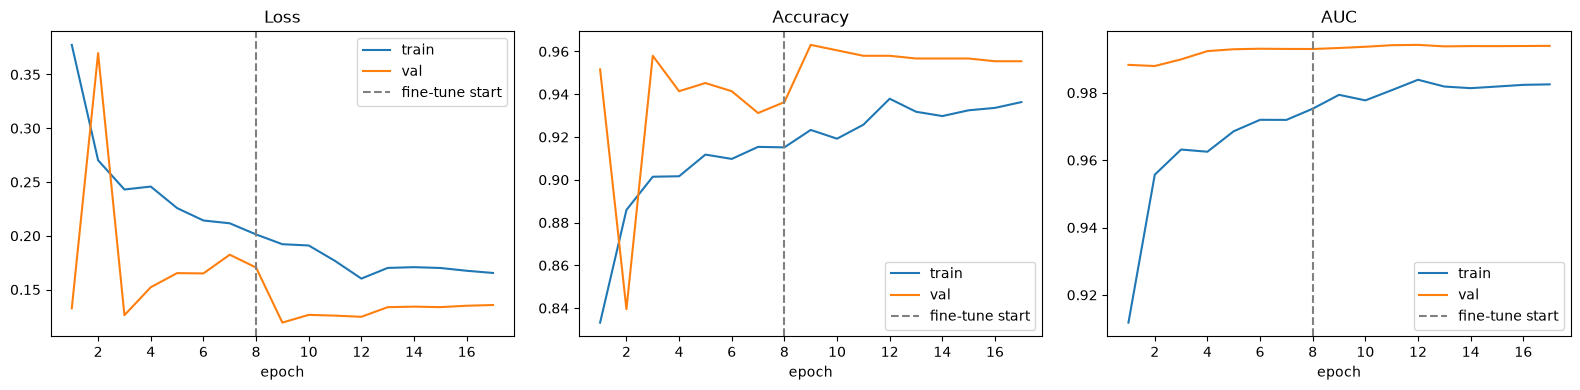

In [21]:
def merge_hist(*hs):
    out = {}
    for h in hs:
        for k, v in h.history.items():
            out.setdefault(k, []).extend(v)
    return out

H = merge_hist(hist1, hist2)
epochs = range(1, len(H["loss"]) + 1)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (k, title) in zip(axes, [("loss", "Loss"), ("acc", "Accuracy"), ("auc", "AUC")]):
    ax.plot(epochs, H[k], label="train"); ax.plot(epochs, H["val_" + k], label="val")
    ax.axvline(len(hist1.history["loss"]), color="gray", ls="--", label="fine-tune start")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.show()

## 4. Evaluation on the official test set
Missing a pneumonia case (false negative) is worse than a false alarm, so we track **recall** closely and also tune the decision threshold on the validation set.

In [22]:
def get_probs(ds):
    y_true = np.concatenate([y.numpy() for _, y in ds]).astype(int)
    y_prob = model.predict(ds, verbose=0).ravel()
    return y_true, y_prob

yv, pv = get_probs(val_ds)
yt, pt = get_probs(test_ds)

# Threshold tuned on VALIDATION data (maximise F1), then applied to test
thresholds = np.linspace(0.05, 0.95, 91)
f1s = [f1_score(yv, pv >= t) for t in thresholds]
best_t = float(thresholds[int(np.argmax(f1s))])
print(f"Best val threshold (max F1): {best_t:.2f}")

for t, name in [(0.5, "default 0.50"), (best_t, f"tuned {best_t:.2f}")]:
    print(f"\n===== TEST @ threshold {name} =====")
    print(classification_report(yt, (pt >= t).astype(int), target_names=CLASS_NAMES, digits=4))

Best val threshold (max F1): 0.26

===== TEST @ threshold default 0.50 =====
              precision    recall  f1-score   support

      NORMAL     0.9101    0.6923    0.7864       234
   PNEUMONIA     0.8386    0.9590    0.8947       390

    accuracy                         0.8590       624
   macro avg     0.8743    0.8256    0.8406       624
weighted avg     0.8654    0.8590    0.8541       624


===== TEST @ threshold tuned 0.26 =====
              precision    recall  f1-score   support

      NORMAL     0.9592    0.6026    0.7402       234
   PNEUMONIA     0.8050    0.9846    0.8858       390

    accuracy                         0.8413       624
   macro avg     0.8821    0.7936    0.8130       624
weighted avg     0.8628    0.8413    0.8312       624



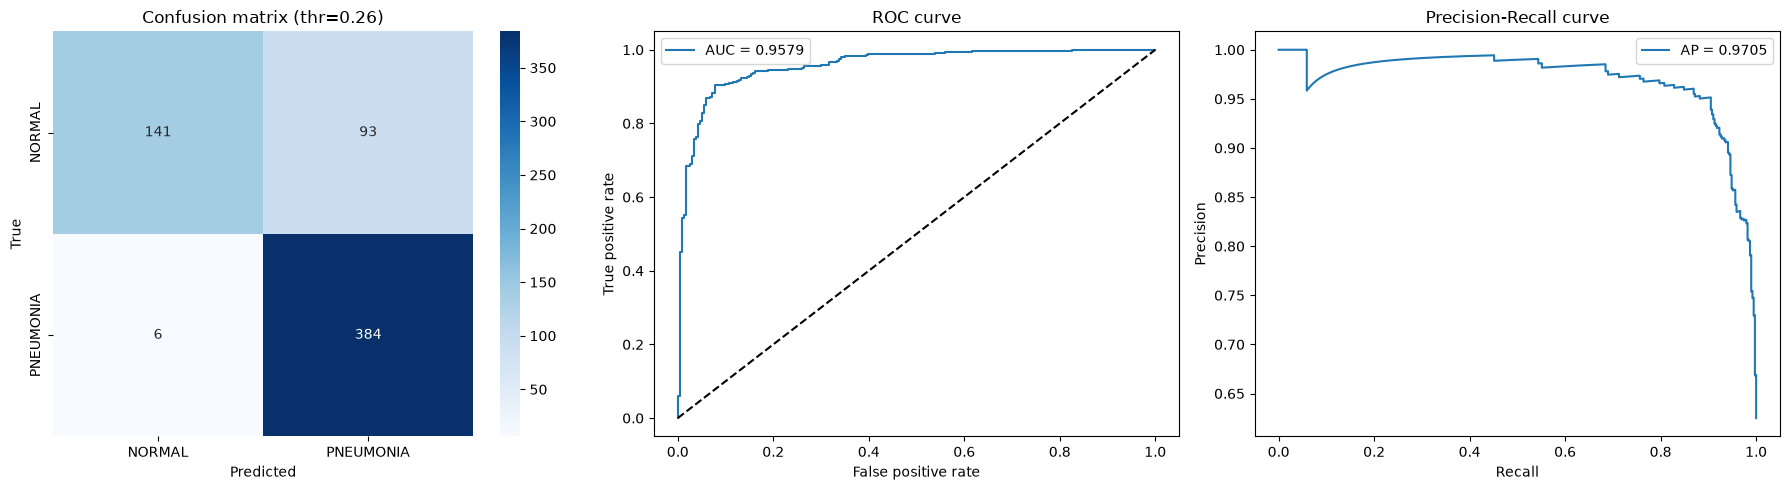

Sensitivity (recall): 0.9846 | Specificity: 0.6026


In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Confusion matrix (tuned threshold)
cm = confusion_matrix(yt, (pt >= best_t).astype(int))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_title(f"Confusion matrix (thr={best_t:.2f})"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True")

# ROC
fpr, tpr, _ = roc_curve(yt, pt); roc_auc = auc(fpr, tpr)
axes[1].plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}"); axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_title("ROC curve"); axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate"); axes[1].legend()

# Precision-Recall
prec, rec, _ = precision_recall_curve(yt, pt); ap = average_precision_score(yt, pt)
axes[2].plot(rec, prec, label=f"AP = {ap:.4f}")
axes[2].set_title("Precision-Recall curve"); axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision"); axes[2].legend()
plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Sensitivity (recall): {tp/(tp+fn):.4f} | Specificity: {tn/(tn+fp):.4f}")

**Note on the test set:** the official test set is small (624 images) and its distribution differs a bit from train, so expect NORMAL recall to be lower than PNEUMONIA recall. Don't over-trust a single number.

## 5. Explainability with Grad-CAM
Checks that the model looks at the lungs rather than markers, text or borders.

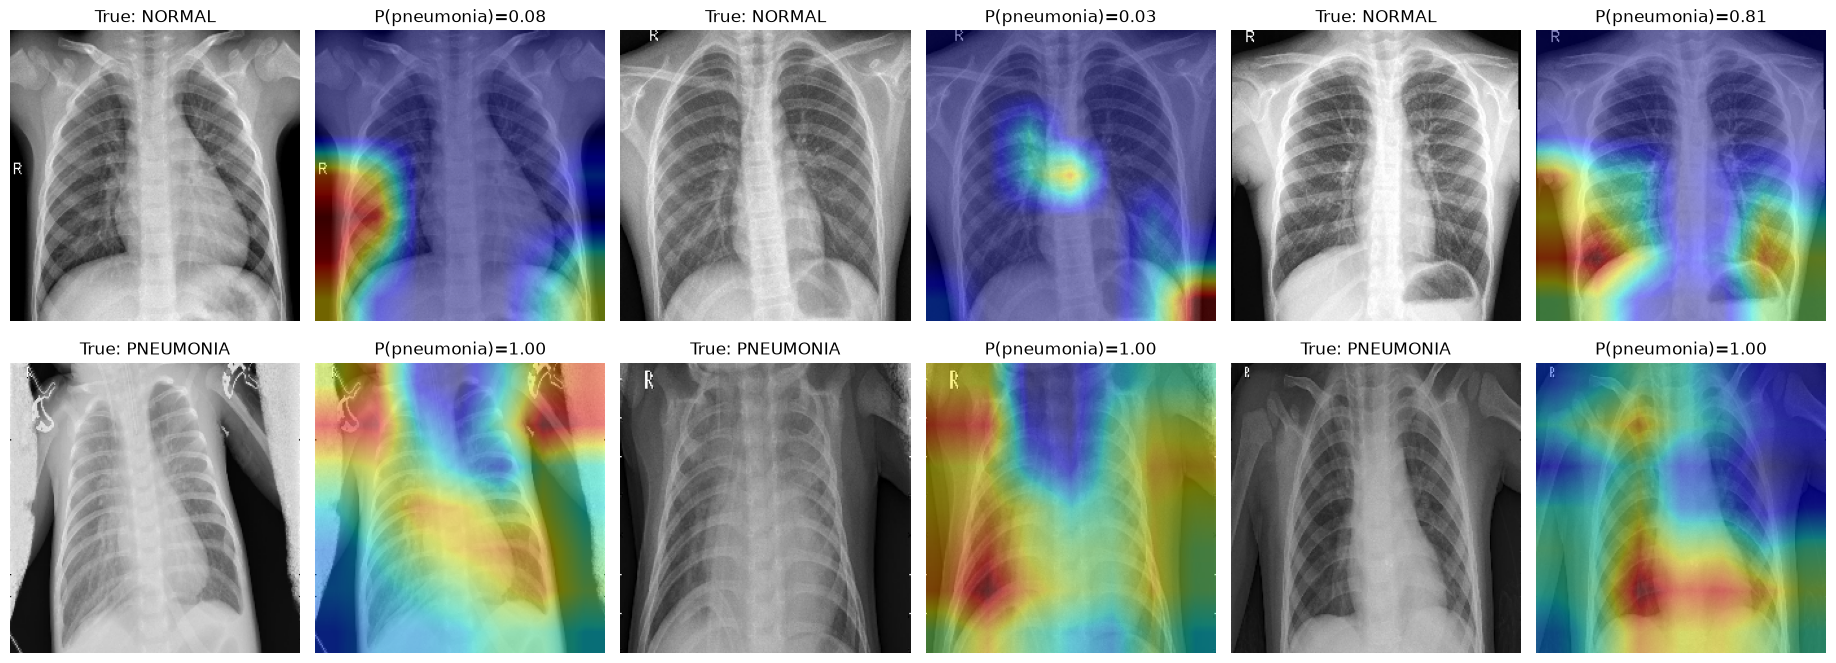

In [24]:
LAST_CONV = "relu"   # final activation of DenseNet121 (7x7x1024)
grad_model = keras.Model(model.input, [model.get_layer(LAST_CONV).output, model.output])

def gradcam(img_batch):
    with tf.GradientTape() as tape:
        conv_out, pred = grad_model(img_batch)
        loss = pred[:, 0]
    grads = tape.gradient(loss, conv_out)
    weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(weights * conv_out, axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return cam.numpy(), float(pred[0, 0])

def load_for_model(path):
    raw = keras.utils.load_img(path, target_size=IMG_SIZE)
    arr = keras.utils.img_to_array(raw)
    return arr.astype("uint8"), preprocess_input(arr[None].copy())

def show_gradcam(df, n=3):
    fig, axes = plt.subplots(2, n * 2, figsize=(4 * n * 2 / 1.3, 7))
    for r, cls in enumerate(CLASS_NAMES):
        subset = df[df["class"] == cls].sample(n, random_state=7)
        for i, p in enumerate(subset["path"]):
            raw, x = load_for_model(p)
            cam, prob = gradcam(x)
            cam_up = tf.image.resize(cam[..., None], IMG_SIZE).numpy().squeeze()
            axes[r, 2 * i].imshow(raw); axes[r, 2 * i].axis("off")
            axes[r, 2 * i].set_title(f"True: {cls}")
            axes[r, 2 * i + 1].imshow(raw); axes[r, 2 * i + 1].imshow(cam_up, cmap="jet", alpha=0.45)
            axes[r, 2 * i + 1].axis("off"); axes[r, 2 * i + 1].set_title(f"P(pneumonia)={prob:.2f}")
    plt.tight_layout(); plt.show()

show_gradcam(test_df)

## 6. Error analysis

Misclassified: 99 / 624


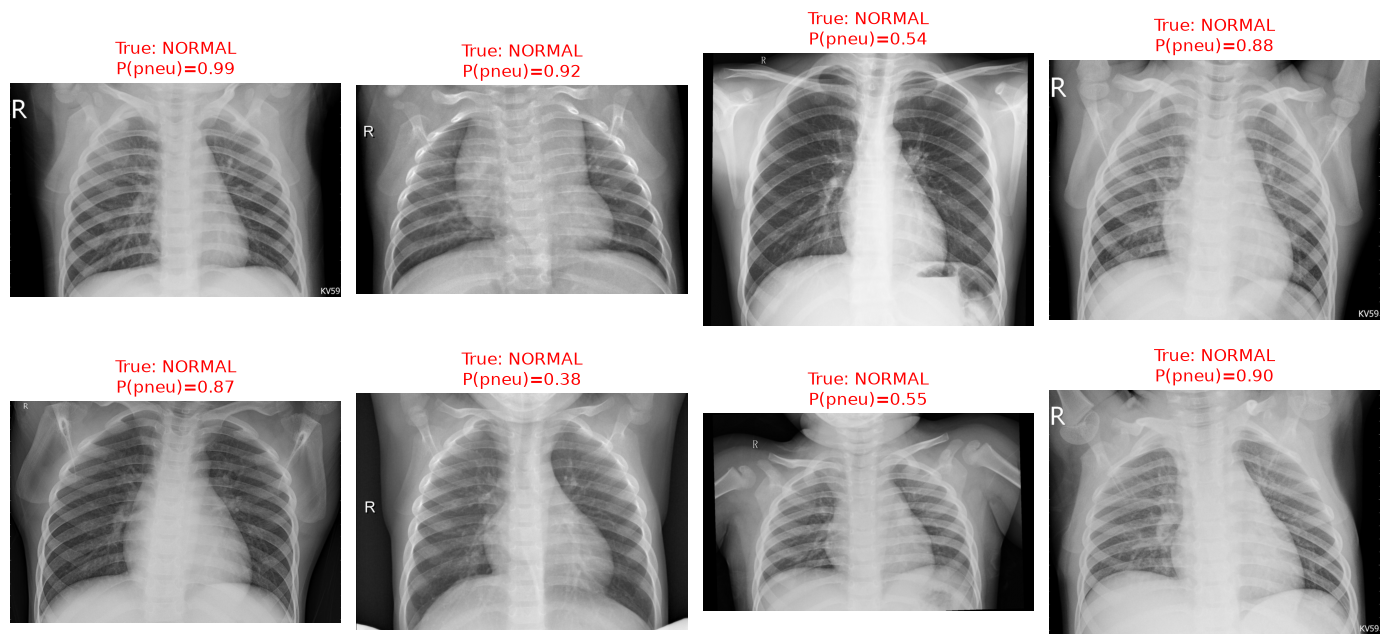

In [25]:
test_df_eval = test_df.copy()
test_df_eval["prob"] = pt
test_df_eval["pred"] = (pt >= best_t).astype(int)
wrong = test_df_eval[test_df_eval["pred"] != test_df_eval["label"]].sort_values("prob")
print(f"Misclassified: {len(wrong)} / {len(test_df_eval)}")

n = min(8, len(wrong))
if n:
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for ax, (_, row) in zip(axes.ravel(), wrong.sample(n, random_state=1).iterrows()):
        ax.imshow(keras.utils.load_img(row["path"], color_mode="grayscale"), cmap="gray"); ax.axis("off")
        ax.set_title(f"True: {row['class']}\nP(pneu)={row['prob']:.2f}", color="red")
    plt.tight_layout(); plt.show()

## 7. Save the model & predict on a new image

In [26]:
model.save("outputs/pneumonia_densenet121.keras")
with open("outputs/threshold.txt", "w") as f:
    f.write(str(best_t))
print("Saved to outputs/")

def predict_image(path, threshold=best_t, show=True):
    raw, x = load_for_model(path)
    cam, prob = gradcam(x)
    label = "PNEUMONIA" if prob >= threshold else "NORMAL"
    if show:
        cam_up = tf.image.resize(cam[..., None], IMG_SIZE).numpy().squeeze()
        fig, ax = plt.subplots(1, 2, figsize=(8, 4))
        ax[0].imshow(raw); ax[0].set_title("Input"); ax[0].axis("off")
        ax[1].imshow(raw); ax[1].imshow(cam_up, cmap="jet", alpha=0.45)
        ax[1].set_title(f"{label} (p={prob:.2f})"); ax[1].axis("off")
        plt.show()
    return label, prob

# Example:
# predict_image(test_df['path'].iloc[0])

Saved to outputs/


In [27]:
os.makedirs("outputs/images", exist_ok=True)

def save(fig, name):
    fig.savefig(f"outputs/images/{name}.png", dpi=200, bbox_inches="tight")
    plt.close(fig)

# 1. Training curves
epochs = range(1, len(H["loss"]) + 1)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (k, t) in zip(axes, [("loss", "Loss"), ("acc", "Accuracy"), ("auc", "AUC")]):
    ax.plot(epochs, H[k], label="train"); ax.plot(epochs, H["val_" + k], label="val")
    ax.axvline(len(hist1.history["loss"]), color="gray", ls="--", label="fine-tune start")
    ax.set_title(t); ax.set_xlabel("epoch"); ax.legend()
save(fig, "1_training_curves")

# 2. Confusion matrix
cm = confusion_matrix(yt, (pt >= best_t).astype(int))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_title(f"Confusion matrix (thr={best_t:.2f})"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
save(fig, "2_confusion_matrix")

# 3. ROC curve
fpr, tpr, _ = roc_curve(yt, pt)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(fpr, tpr, label=f"AUC = {auc(fpr, tpr):.4f}"); ax.plot([0, 1], [0, 1], "k--")
ax.set_title("ROC curve"); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.legend()
save(fig, "3_roc_curve")

# 4. Precision-Recall curve
prec, rec, _ = precision_recall_curve(yt, pt)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(rec, prec, label=f"AP = {average_precision_score(yt, pt):.4f}")
ax.set_title("Precision-Recall curve"); ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.legend()
save(fig, "4_precision_recall_curve")

# 5. Grad-CAM examples (one image file per sample)
for cls in CLASS_NAMES:
    for i, p in enumerate(test_df[test_df["class"] == cls].sample(3, random_state=7)["path"]):
        raw, x = load_for_model(p)
        cam, prob = gradcam(x)
        cam_up = tf.image.resize(cam[..., None], IMG_SIZE).numpy().squeeze()
        fig, ax = plt.subplots(1, 2, figsize=(8, 4))
        ax[0].imshow(raw); ax[0].set_title(f"True: {cls}"); ax[0].axis("off")
        ax[1].imshow(raw); ax[1].imshow(cam_up, cmap="jet", alpha=0.45)
        ax[1].set_title(f"P(pneumonia)={prob:.2f}"); ax[1].axis("off")
        save(fig, f"5_gradcam_{cls.lower()}_{i+1}")

# 6. Misclassified examples
wrong = test_df_eval[test_df_eval["pred"] != test_df_eval["label"]]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (_, row) in zip(axes.ravel(), wrong.sample(min(8, len(wrong)), random_state=1).iterrows()):
    ax.imshow(keras.utils.load_img(row["path"], color_mode="grayscale"), cmap="gray"); ax.axis("off")
    ax.set_title(f"True: {row['class']}\nP(pneu)={row['prob']:.2f}", color="red")
save(fig, "6_misclassified_examples")

print(sorted(os.listdir("outputs/images")))

['1_training_curves.png', '2_confusion_matrix.png', '3_roc_curve.png', '4_precision_recall_curve.png', '5_gradcam_normal_1.png', '5_gradcam_normal_2.png', '5_gradcam_normal_3.png', '5_gradcam_pneumonia_1.png', '5_gradcam_pneumonia_2.png', '5_gradcam_pneumonia_3.png', '6_misclassified_examples.png']


## Ideas to improve
- Try `EfficientNetB0`/`ResNet50` and compare AUC
- Ensemble several models, use test-time augmentation
- Use k-fold cross-validation (patient-level splits if patient IDs are available, since images from one patient can leak across splits)
- Try focal loss for the class imbalance
- Add bacterial vs viral sub-classification (filenames contain `bacteria` / `virus`)